# 05 V7 — Web Attack Specialist | CIC-IDS2017 (60 features)

**Mục tiêu:** Xác định liệu phân loại phụ hai lớp **Web Attack Brute Force / Web Attack XSS** có giảm nhầm lẫn cho CNN–SE–Feature Attention V6 hay không. V7 **không thay thế** CNN V6 bằng LightGBM: đây là một *hybrid/specialist experiment* và phải được báo cáo riêng với CNN thuần túy.

- Input bắt buộc: output **Notebook 03B** (`cic_expanded_splits.parquet`, `feature_sets.json`, `experiment_manifest.json`) và output **Notebook 05 V6** (`selected_best.pt`, `selected_preprocessing.joblib`, `validation_selection.json` hoặc `final_test_metrics.json`). Dùng **Add Input** trên Kaggle và **Save Version** của cả hai notebook.
- Sử dụng **chính xác split 03B**, kiểm tra hash SHA256, tên 60 features, thứ tự nhãn, kiến trúc và metadata checkpoint. Không tái chia dữ liệu.
- Huấn luyện specialist **chỉ trên train** có nhãn Brute Force hoặc XSS; chọn candidate và ngưỡng bằng **validation 15 lớp**, quyết định cuối cùng mới đánh giá **test một lần**.
- SQL Injection **không** được giả vờ học ổn định vì chỉ có 16 mẫu train; V7 giữ nguyên dự đoán SQL của CNN V6.
- Do test pilot đã được xem ở V6, kết quả V7 là **exploratory**, không phải một phép đánh giá cuối hoàn toàn độc lập. **Không chọn lại** sau khi xem test V7.
- Sử dụng CPU/GPU đều được (CNN trên GPU nếu có; specialist chạy CPU).

## 1. Môi trường, vị trí input và cấu hình

In [8]:
from pathlib import Path
import json, hashlib, warnings, time
import numpy as np, pandas as pd, torch, joblib
from torch import nn
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

SEED = 42
INPUT_03B_DIR = None  # Hoặc Path('/kaggle/input/.../03B_CIC_Feature_Engineering')
INPUT_V6_DIR = None   # Hoặc Path('/kaggle/input/.../05_CNN_Ablation_V6_Expanded')
OUT = Path('/kaggle/working/nids_outputs/05_V7_Web_Attack_Specialist') if Path('/kaggle/working').exists() else Path('reports/notebook_outputs/05_V7_Web_Attack_Specialist')
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
np.random.seed(SEED);torch.manual_seed(SEED)
print('Device:',DEVICE)

def find_one(required, manual, label):
    if manual is not None:
        options=[Path(manual)]
    else:
        roots=[p for p in [Path('/kaggle/input'),Path('/kaggle/working/nids_outputs')] if p.exists()]
        options=sorted({p.parent for root in roots for p in root.rglob(required[0])})
    options=[p for p in options if all((p/f).is_file() for f in required)]
    if len(options)!=1:
        raise FileNotFoundError(f'{label}: cần đúng một thư mục chứa {required}, tìm thấy: {options}. Hãy Add Input output tương ứng hoặc đặt INPUT_*_DIR.')
    return options[0]

p03=find_one(['cic_expanded_splits.parquet','feature_sets.json','experiment_manifest.json'],INPUT_03B_DIR,'03B')
pv6=find_one(['selected_best.pt','selected_preprocessing.joblib'],INPUT_V6_DIR,'V6')
print('03B:',p03,'\nV6:',pv6)

Device: cuda
03B: /kaggle/input/datasets/chienvoo/nids-outputs/nids_outputs_backup/nids_outputs/03B_CIC_Feature_Engineering 
V6: /kaggle/input/datasets/chienvoo/nids-outputs/nids_outputs_backup/nids_outputs/05_CNN_Ablation_V6_Expanded


## 2. Khóa cùng dữ liệu, label encoding, preprocessing và checkpoint V6

In [9]:
split_file=p03/'cic_expanded_splits.parquet'
split_sha=hashlib.sha256(split_file.read_bytes()).hexdigest()
df=pd.read_parquet(split_file)
source_manifest=json.loads((p03/'experiment_manifest.json').read_text(encoding='utf8'))
feature_sets=json.loads((p03/'feature_sets.json').read_text(encoding='utf8'))
prep=joblib.load(pv6/'selected_preprocessing.joblib')
features=list(prep['features'])
variant=prep['feature_variant']
enc=prep['label_encoder']
classes=list(enc.classes_)
assert len(features)==60 and features==list(feature_sets[variant]), 'Feature schema/order mismatch'
assert prep['split_sha256']==split_sha, 'Split SHA mismatch versus V6 preprocessing'
assert len(df)==int(source_manifest['sample_rows'])
assert df.groupby('_duplicate_group')['_split'].nunique().max()==1
assert not df.duplicated(['_source_file','_source_row']).any()
assert set(df['_split'])=={'train','val','test'}
assert set(df['Label'].astype(str))==set(classes)
assert all(c in df.columns for c in features)
assert not any(c.startswith('_') or c=='Label' for c in features)

idx={s:df['_split'].eq(s).to_numpy() for s in ['train','val','test']}
y={s:enc.transform(df.loc[idx[s],'Label'].astype(str)).astype(np.int64) for s in idx}
raw=df[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
X={s:prep['scaler'].transform(prep['imputer'].transform(raw.loc[idx[s]])).astype('float32') for s in idx}
for s in idx:
    assert np.isfinite(X[s]).all() and X[s].shape==(idx[s].sum(),60)

web_bf=next(n for n in classes if 'Web Attack' in n and 'Brute Force' in n)
web_xss=next(n for n in classes if 'Web Attack' in n and 'XSS' in n)
bf_id=classes.index(web_bf);xss_id=classes.index(web_xss);benign_id=classes.index('BENIGN')
print('split SHA256:',split_sha)
print('rows:',{s:len(y[s]) for s in y},'features:',len(features),'classes:',len(classes))
print('Web labels:',repr(web_bf),repr(web_xss))
print('Web train support:',{name:int((y['train']==i).sum()) for name,i in [('BF',bf_id),('XSS',xss_id)]})
assert min((y['train']==bf_id).sum(),(y['train']==xss_id).sum())>0

ck=torch.load(pv6/'selected_best.pt',map_location='cpu',weights_only=True)
assert ck['split_sha256']==split_sha,'V6 checkpoint trained on different split'
assert list(ck['features'])==features,'V6 checkpoint feature mismatch'
assert list(ck['classes'])==classes,'V6 checkpoint class order mismatch'
vcfg=ck['config']
if (pv6/'validation_selection.json').exists():
    base_bias=float(json.loads((pv6/'validation_selection.json').read_text(encoding='utf8'))['bias'])
elif (pv6/'final_test_metrics.json').exists():
    base_bias=float(json.loads((pv6/'final_test_metrics.json').read_text(encoding='utf8'))['bias'])
else:
    raise FileNotFoundError('V6 missing validation_selection.json or final_test_metrics.json (needed to recover fixed validation-selected bias)')
print('V6 arch:',vcfg['arch'],'scaler:',vcfg['scaler'],'bias selected previously:',base_bias)
assert base_bias==float(base_bias)

# Explicitly record reproducibility, never import user-provided predictions as labels.
(OUT/'input_manifest.json').write_text(json.dumps({'split_sha256':split_sha,'source_03b':str(p03),'source_v6':str(pv6),'features':features,'classes':classes,'v6_config':vcfg,'v6_base_bias':base_bias},ensure_ascii=False,indent=2),encoding='utf8')

split SHA256: d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152
rows: {'train': 23922, 'val': 7862, 'test': 7409} features: 60 classes: 15
Web labels: 'Web Attack ï¿½ Brute Force' 'Web Attack ï¿½ XSS'
Web train support: {'BF': 945, 'XSS': 388}
V6 arch: A5_no_Raw scaler: standard bias selected previously: 1.0


2334

## 3. Khôi phục đúng kiến trúc CNN–SE–Attention V6, không train lại

In [10]:
class SEBlock(nn.Module):
    def __init__(self,c,reduction=8):
        super().__init__()
        self.net=nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten(),
            nn.Linear(c,max(4,c//reduction)),nn.ReLU(),nn.Linear(max(4,c//reduction),c),nn.Sigmoid())
    def forward(self,z):return z*self.net(z).unsqueeze(-1)

class AttentionPool(nn.Module):
    def __init__(self,c):
        super().__init__();self.score=nn.Sequential(nn.Linear(c,max(8,c//2)),nn.Tanh(),nn.Linear(max(8,c//2),1))
    def forward(self,z):
        h=z.transpose(1,2)
        w=torch.softmax(self.score(h).squeeze(-1),dim=1)
        return (h*w.unsqueeze(-1)).sum(dim=1)

class BasicFeatureCNN(nn.Module):
    def __init__(self,f,k,use_se=False,use_attn=False,width=64,dropout=.2):
        super().__init__();self.f=f
        self.conv=nn.Sequential(nn.Conv1d(1,width,3,padding=1),nn.ReLU(),nn.Conv1d(width,width,3,padding=1),nn.ReLU())
        self.se=SEBlock(width) if use_se else nn.Identity()
        self.pool=AttentionPool(width) if use_attn else nn.AdaptiveAvgPool1d(1)
        self.head=nn.Sequential(nn.Linear(width,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):
        z=self.se(self.conv(x.unsqueeze(1)))
        h=self.pool(z)
        if h.ndim==3:h=h.squeeze(-1)
        return self.head(h)

class ResConvBlock(nn.Module):
    def __init__(self,c,dropout):
        super().__init__()
        self.net=nn.Sequential(nn.Conv1d(c,c,3,padding=1),nn.BatchNorm1d(c),nn.GELU(),
                nn.Conv1d(c,c,3,padding=1),nn.BatchNorm1d(c))
        self.drop=nn.Dropout1d(dropout)
    def forward(self,x):return torch.nn.functional.gelu(x+self.drop(self.net(x)))

class MultiScaleResidualCNN(nn.Module):
    def __init__(self,f,k,width=64,dropout=.2,use_se=True,use_attn=True,hybrid=False):
        super().__init__();self.f=f;self.hybrid=hybrid
        self.multi=nn.ModuleList([nn.Conv1d(1,width,sz,padding=sz//2) for sz in [1,3,5]])
        self.proj=nn.Sequential(nn.Conv1d(width*3,width,1),nn.BatchNorm1d(width),nn.GELU())
        self.blocks=nn.Sequential(ResConvBlock(width,dropout),ResConvBlock(width,dropout))
        self.se=SEBlock(width) if use_se else nn.Identity()
        self.pool=AttentionPool(width) if use_attn else nn.AdaptiveAvgPool1d(1)
        # Attention + avg/max retain both focused and global information.
        merged=width*3
        if hybrid:
            self.raw_path=nn.Sequential(nn.Linear(f,128),nn.LayerNorm(128),nn.GELU(),
                          nn.Dropout(dropout),nn.Linear(128,width),nn.GELU())
            merged+=width
        self.head=nn.Sequential(nn.Linear(merged,128),nn.GELU(),nn.Dropout(dropout),
                                nn.Linear(128,64),nn.GELU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):
        z=self.proj(torch.cat([part(x.unsqueeze(1)) for part in self.multi],dim=1))
        z=self.se(self.blocks(z))
        h=self.pool(z)
        if h.ndim==3:h=h.squeeze(-1)
        pieces=[h,z.mean(-1),z.amax(-1)]
        if self.hybrid:pieces.append(self.raw_path(x))
        return self.head(torch.cat(pieces,dim=1))

class MLPBaseline(nn.Module):
    def __init__(self,f,k,dropout=.2,width=128):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(f,width),nn.ReLU(),nn.Dropout(dropout),
             nn.Linear(width,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):return self.net(x)

ARCHS=['MLP','A0_CNN','A1_CNN_SE','A2_CNN_FeatureAttn','A3_CNN_SE_FeatureAttn',
       'A4_MultiScaleRes_SE_Attn','A5_HybridMultiScaleRes_SE_Attn']
def build_model(arch,width=64,dropout=.2):
    f=len(features);k=len(classes)  # classes được tạo ở cell đọc dữ liệu 03B
    if arch=='MLP':return MLPBaseline(f,k,dropout,width=max(128,width))
    if arch.startswith('A0_'):return BasicFeatureCNN(f,k,False,False,width,dropout)
    if arch.startswith('A1_'):return BasicFeatureCNN(f,k,True,False,width,dropout)
    if arch.startswith('A2_'):return BasicFeatureCNN(f,k,False,True,width,dropout)
    if arch.startswith('A3_'):return BasicFeatureCNN(f,k,True,True,width,dropout)
    if arch.startswith('A4_'):return MultiScaleResidualCNN(f,k,width,dropout,hybrid=False)
    if arch=='A5_HybridMultiScaleRes_SE_Attn':return MultiScaleResidualCNN(f,k,width,dropout,True,True,True)
    if arch=='A5_no_SE':return MultiScaleResidualCNN(f,k,width,dropout,False,True,True)
    if arch=='A5_no_Attn':return MultiScaleResidualCNN(f,k,width,dropout,True,False,True)
    if arch=='A5_no_Raw':return MultiScaleResidualCNN(f,k,width,dropout,True,True,False)
    if arch=='A5_backbone_only':return MultiScaleResidualCNN(f,k,width,dropout,False,False,False)
    raise ValueError(arch)


model=build_model(vcfg['arch'],int(vcfg['width']),float(vcfg['dropout'])).to(DEVICE)
model.load_state_dict(ck['state_dict'],strict=True)
model.eval()
@torch.inference_mode()
def v6_logits(which,batch=1024):
    x=X[which]
    out=[]
    for start in range(0,len(x),batch):
        xb=torch.from_numpy(x[start:start+batch]).to(DEVICE)
        out.append(model(xb).cpu().float().numpy())
    return np.concatenate(out,axis=0)

def base_predict(z):
    a=z.copy();a[:,benign_id]+=base_bias
    return a.argmax(1)

val_logit=v6_logits('val');base_val=base_predict(val_logit)
print('Restored V6 model, validation predictions:',len(base_val))

Restored V6 model, validation predictions: 7862


## 4. Error Analysis chỉ trên validation: XSS → Brute Force và cặp nhầm lẫn

In [11]:
def full_metrics(truth,pred):
    is_attack=np.asarray(truth)!=benign_id;reported_attack=np.asarray(pred)!=benign_id
    tn=int(((~is_attack)&(~reported_attack)).sum());fp=int(((~is_attack)&reported_attack).sum())
    rep=classification_report(truth,pred,labels=np.arange(len(classes)),target_names=classes,output_dict=True,zero_division=0)
    return {'accuracy':float(accuracy_score(truth,pred)),
            'macro_f1':float(f1_score(truth,pred,labels=np.arange(len(classes)),average='macro',zero_division=0)),
            'fpr':float(fp/(tn+fp)),
            'attack_recall':float(recall_score(is_attack,reported_attack,zero_division=0)),
            'xss_f1':float(rep[web_xss]['f1-score']),
            'xss_recall':float(rep[web_xss]['recall']),
            'bf_precision':float(rep[web_bf]['precision'])}

def confusion_pairs(truth,pred):
    tab=pd.DataFrame({'true':np.array(classes)[truth],'pred':np.array(classes)[pred]})
    return (tab[tab['true']!=tab['pred']].groupby(['true','pred']).size()
            .reset_index(name='count').sort_values('count',ascending=False))

base_val_metrics=full_metrics(y['val'],base_val)
print('V6 baseline VAL:',base_val_metrics)
display(confusion_pairs(y['val'],base_val).head(20))
confusion_pairs(y['val'],base_val).to_csv(OUT/'v6_validation_confusion_pairs.csv',index=False)
base_vr=classification_report(y['val'],base_val,labels=np.arange(len(classes)),target_names=classes,output_dict=True,zero_division=0)
pd.DataFrame(base_vr).T.to_csv(OUT/'v6_validation_classification_report.csv')

# Where do base predictions route? Do not route based on true labels.
route_val=np.isin(base_val,[bf_id,xss_id])
print('Validation predicted BF/XSS routed:',int(route_val.sum()))
print('Among true XSS routed:',int((route_val & (y['val']==xss_id)).sum()),'of',int((y['val']==xss_id).sum()))
print('Among true BF routed:',int((route_val & (y['val']==bf_id)).sum()),'of',int((y['val']==bf_id).sum()))

V6 baseline VAL: {'accuracy': 0.9688374459425083, 'macro_f1': 0.8565861599752004, 'fpr': 0.0533625730994152, 'attack_recall': 0.9984601170311056, 'xss_f1': 0.10144927536231885, 'xss_recall': 0.05384615384615385, 'bf_precision': 0.6745406824146981}


,true,pred,count
30,Web Attack ï¿½ XSS,Web Attack ï¿½ Brute Force,121
0,BENIGN,Bot,31
6,BENIGN,PortScan,22
26,Web Attack ï¿½ Brute Force,SSH-Patator,11
3,BENIGN,DoS Hulk,6
13,DoS Hulk,BENIGN,5
15,DoS Slowhttptest,DoS slowloris,4
12,DoS GoldenEye,Web Attack ï¿½ Sql Injection,4
24,SSH-Patator,DoS GoldenEye,4
18,DoS slowloris,DoS Slowhttptest,4


Validation predicted BF/XSS routed: 389
Among true XSS routed: 128 of 130
Among true BF routed: 258 of 269


## 5. Phân tích 60 features trên train (không dùng test)

In [12]:
webtrain=np.isin(y['train'],[bf_id,xss_id])
xt=X['train'][webtrain]
yt=(y['train'][webtrain]==xss_id).astype(int)
mu_xss=xt[yt==1].mean(axis=0);mu_bf=xt[yt==0].mean(axis=0)
pooled=(xt[yt==1].var(axis=0)+xt[yt==0].var(axis=0))/2
contrast=pd.DataFrame({'feature':features,'xss_mean_scaled':mu_xss,'bf_mean_scaled':mu_bf,'cohen_d':(mu_xss-mu_bf)/np.sqrt(pooled+1e-8)})
contrast['abs_d']=contrast['cohen_d'].abs()
contrast=contrast.sort_values('abs_d',ascending=False)
contrast.to_csv(OUT/'web_feature_contrasts_train.csv',index=False)
display(contrast.head(20))
print('Cohen d chỉ là độ khác biệt phân phối, KHÔNG chứng minh đặc trưng phân biệt được mẫu mới.')

,feature,xss_mean_scaled,bf_mean_scaled,cohen_d,abs_d
45,Down/Up Ratio,-0.685252,-0.496767,-0.550445,0.550445
44,URG Flag Count,-0.310332,0.007589,-0.427871,0.427871
49,Init_Win_bytes_backward,3.234351,2.777570,0.356319,0.356319
34,Bwd Packets/s,-0.183115,-0.136871,-0.339895,0.339895
26,Bwd IAT Mean,-0.287897,-0.280538,-0.275291,0.275291
48,Init_Win_bytes_forward,1.057058,0.922790,0.270299,0.270299
42,PSH Flag Count,0.854700,0.719065,0.267587,0.267587
43,ACK Flag Count,-0.670780,-0.529693,-0.267578,0.267578
18,Flow IAT Max,-0.362164,-0.375020,0.265736,0.265736
21,Fwd IAT Mean,-0.216163,-0.229007,0.259103,0.259103


Cohen d chỉ là độ khác biệt phân phối, KHÔNG chứng minh đặc trưng phân biệt được mẫu mới.


## 6. Huấn luyện các specialist trên train Web BF/XSS (không dùng validation làm training)

In [13]:
models={
 'LogisticRegression':LogisticRegression(max_iter=1800,class_weight='balanced',C=1.0,random_state=SEED),
 'ExtraTrees':ExtraTreesClassifier(n_estimators=300,min_samples_leaf=2,max_features='sqrt',class_weight='balanced',n_jobs=-1,random_state=SEED),
}
try:
    from lightgbm import LGBMClassifier
    models['LightGBM']=LGBMClassifier(objective='binary',n_estimators=250,learning_rate=0.035,
        num_leaves=15,max_depth=5,min_child_samples=12,reg_lambda=2.,class_weight='balanced',random_state=SEED,verbosity=-1,n_jobs=2)
except ImportError:
    warnings.warn('LightGBM unavailable; LogisticRegression and ExtraTrees will still be evaluated.')

fitted={};special_val={}
for name,est in models.items():
    t0=time.time();est.fit(xt,yt)
    fitted[name]=est
    special_val[name]=est.predict_proba(X['val'])[:,list(est.classes_).index(1)]
    print(name,'trained on',len(yt),'train Web flows; train class counts:',np.bincount(yt).tolist(),'seconds:',round(time.time()-t0,2))
    joblib.dump(est,OUT/f'web_specialist_{name}.joblib')
assert all(len(z)==len(y['val']) for z in special_val.values())

LogisticRegression trained on 1333 train Web flows; train class counts: [945, 388] seconds: 0.05
ExtraTrees trained on 1333 train Web flows; train class counts: [945, 388] seconds: 0.76
LightGBM trained on 1333 train Web flows; train class counts: [945, 388] seconds: 0.2


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 7. Chọn mô hình, ngưỡng và cơ chế định tuyến bằng **validation 15 lớp**

In [14]:
# Router: chỉ những mẫu CNN dự đoán BF/XSS mới được specialist xem xét.
# Mẫu CNN dự đoán BENIGN, Bot, SQL Injection... không bị tự động gửi vào specialist.
# Optional confidence gate: override only if specialist is confident in XSS or BF.
THRESHOLDS=[0.10,0.20,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.80,0.90]
GATES=[0.50,0.60,0.70,0.80,0.90]

def combined_pred(base,prob,threshold,gate):
    pred=base.copy()
    mask=np.isin(base,[bf_id,xss_id])
    specialist_pred=np.where(prob>=threshold,xss_id,bf_id)
    specialist_conf=np.where(prob>=threshold,prob,1-prob)
    mask=mask & (specialist_conf>=gate)
    pred[mask]=specialist_pred[mask]
    return pred

records=[]
for name,prob in special_val.items():
    for threshold in THRESHOLDS:
        for gate in GATES:
            pred=combined_pred(base_val,prob,threshold,gate)
            records.append({'specialist':name,'threshold':threshold,'gate':gate,**full_metrics(y['val'],pred)})
search=pd.DataFrame(records)
search.to_csv(OUT/'validation_router_grid.csv',index=False)
# Compare against no-specialist before any test evaluation.
selection=search.sort_values(['macro_f1','xss_f1','accuracy'],ascending=False).iloc[0].to_dict()
accept=selection['macro_f1']>base_val_metrics['macro_f1']+1e-6
selection['accepted']=bool(accept)
selection['selection_rule']='validation 15-class macro-F1; strict improvement over V6 baseline required'
(OUT/'validation_selection.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False),encoding='utf8')
print('Base V6 validation:',base_val_metrics)
print('Best specialist validation:',selection)
print('Use specialist?',accept)
display(search.sort_values('macro_f1',ascending=False).head(12))
chosen_val=(combined_pred(base_val,special_val[selection['specialist']],selection['threshold'],selection['gate']) if accept else base_val)
pd.DataFrame(classification_report(y['val'],chosen_val,labels=np.arange(len(classes)),target_names=classes,output_dict=True,zero_division=0)).T.to_csv(OUT/'selected_validation_classification_report.csv')
confusion_pairs(y['val'],chosen_val).to_csv(OUT/'selected_validation_confusion_pairs.csv',index=False)

Base V6 validation: {'accuracy': 0.9688374459425083, 'macro_f1': 0.8565861599752004, 'fpr': 0.0533625730994152, 'attack_recall': 0.9984601170311056, 'xss_f1': 0.10144927536231885, 'xss_recall': 0.05384615384615385, 'bf_precision': 0.6745406824146981}
Best specialist validation: {'specialist': 'LightGBM', 'threshold': 0.4, 'gate': 0.5, 'accuracy': 0.9660391757822437, 'macro_f1': 0.8773662438055475, 'fpr': 0.0533625730994152, 'attack_recall': 0.9984601170311056, 'xss_f1': 0.5358255451713395, 'xss_recall': 0.6615384615384615, 'bf_precision': 0.7878787878787878, 'accepted': True, 'selection_rule': 'validation 15-class macro-F1; strict improvement over V6 baseline required'}
Use specialist? True


,specialist,threshold,gate,accuracy,macro_f1,fpr,attack_recall,xss_f1,xss_recall,bf_precision
155,LightGBM,0.45,0.5,0.966039,0.877366,0.053363,0.99846,0.535826,0.661538,0.787879
150,LightGBM,0.40,0.5,0.966039,0.877366,0.053363,0.99846,0.535826,0.661538,0.787879
160,LightGBM,0.50,0.5,0.966039,0.877366,0.053363,0.99846,0.535826,0.661538,0.787879
130,LightGBM,0.10,0.5,0.965912,0.877065,0.053363,0.99846,0.534161,0.661538,0.786802
140,LightGBM,0.30,0.5,0.965912,0.877065,0.053363,0.99846,0.534161,0.661538,0.786802
145,LightGBM,0.35,0.5,0.965912,0.877065,0.053363,0.99846,0.534161,0.661538,0.786802
135,LightGBM,0.20,0.5,0.965912,0.877065,0.053363,0.99846,0.534161,0.661538,0.786802
100,ExtraTrees,0.55,0.5,0.966166,0.876662,0.053363,0.99846,0.511628,0.592308,0.761468
165,LightGBM,0.55,0.5,0.966294,0.876528,0.053363,0.99846,0.501695,0.569231,0.758929
90,ExtraTrees,0.45,0.5,0.965530,0.876356,0.053363,0.99846,0.536585,0.676923,0.785340


## 8. Một lần đánh giá test sau khi khóa lựa chọn (pilot, không dùng test để đổi lựa chọn)

In [15]:
# Test consulted only here. Save both V6 fixed reference and V7 selected prediction.
test_logits=v6_logits('test');test_base=base_predict(test_logits)
if accept:
    chosen=fitted[selection['specialist']]
    prob=chosen.predict_proba(X['test'])[:,list(chosen.classes_).index(1)]
    test_final=combined_pred(test_base,prob,selection['threshold'],selection['gate'])
else:
    test_final=test_base.copy()

base_test_metrics=full_metrics(y['test'],test_base)
final_test_metrics=full_metrics(y['test'],test_final)
print('V6 test reference (previously exposed, not used for selection):',base_test_metrics)
print('V7 test result (locked validation decision):',final_test_metrics)
results={'protocol':'exploratory_group_exact_duplicates_not_host_time_independent',
 'selected_on':'validation_15class_macro_f1',
 'selected_specialist':selection['specialist'] if accept else None,
 'threshold':selection['threshold'] if accept else None,
 'gate':selection['gate'] if accept else None,
 'baseline_val':base_val_metrics,'selection_val':selection,
 'v6_test':base_test_metrics,'v7_test':final_test_metrics,
 'split_sha256':split_sha,'n_test':len(y['test']),
 'limitation':'Test previously inspected in earlier notebooks; independent external holdout needed for publication claims.'}
(OUT/'final_test_metrics.json').write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding='utf8')
for name,pred in [('v6',test_base),('v7',test_final)]:
    pd.DataFrame(classification_report(y['test'],pred,labels=np.arange(len(classes)),target_names=classes,output_dict=True,zero_division=0)).T.to_csv(OUT/f'{name}_test_classification_report.csv')
    confusion_pairs(y['test'],pred).to_csv(OUT/f'{name}_test_confusion_pairs.csv',index=False)
    np.save(OUT/f'{name}_test_confusion_matrix.npy',confusion_matrix(y['test'],pred,labels=np.arange(len(classes))))

pd.DataFrame({'true_label':np.array(classes)[y['test']],
    'v6_pred_label':np.array(classes)[test_base],
    'v7_pred_label':np.array(classes)[test_final],
    'source_file':df.loc[idx['test'],'_source_file'].to_numpy(),
    'source_row':df.loc[idx['test'],'_source_row'].to_numpy()}).to_csv(OUT/'test_predictions_comparison.csv',index=False)

class_table=pd.DataFrame({'class':classes,'v6_f1':[classification_report(y['test'],test_base,labels=np.arange(len(classes)),target_names=classes,output_dict=True,zero_division=0)[c]['f1-score'] for c in classes],
                         'v7_f1':[classification_report(y['test'],test_final,labels=np.arange(len(classes)),target_names=classes,output_dict=True,zero_division=0)[c]['f1-score'] for c in classes]})
class_table['delta']=class_table.v7_f1-class_table.v6_f1
class_table.to_csv(OUT/'test_per_class_comparison.csv',index=False)
display(class_table.sort_values('delta'))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


V6 test reference (previously exposed, not used for selection): {'accuracy': 0.9634228640842218, 'macro_f1': 0.7990064269306069, 'fpr': 0.06060606060606061, 'attack_recall': 0.9978533685601056, 'xss_f1': 0.07194244604316546, 'xss_recall': 0.03731343283582089, 'bf_precision': 0.6788321167883211}
V7 test result (locked validation decision): {'accuracy': 0.9585639087596167, 'macro_f1': 0.8185248174428573, 'fpr': 0.06060606060606061, 'attack_recall': 0.9978533685601056, 'xss_f1': 0.5229885057471264, 'xss_recall': 0.6791044776119403, 'bf_precision': 0.7772277227722773}


,class,v6_f1,v7_f1,delta
12,Web Attack ï¿½ Brute Force,0.792614,0.634343,-0.158270
0,BENIGN,0.963974,0.963974,0.000000
2,DDoS,0.995601,0.995601,0.000000
1,Bot,0.960298,0.960298,0.000000
4,DoS Hulk,0.988055,0.988055,0.000000
5,DoS Slowhttptest,0.989641,0.989641,0.000000
6,DoS slowloris,0.991404,0.991404,0.000000
3,DoS GoldenEye,0.983273,0.983273,0.000000
7,FTP-Patator,0.992819,0.992819,0.000000
8,Heartbleed,0.666667,0.666667,0.000000


## 9. Đồ thị, tóm tắt và giới hạn khoa học

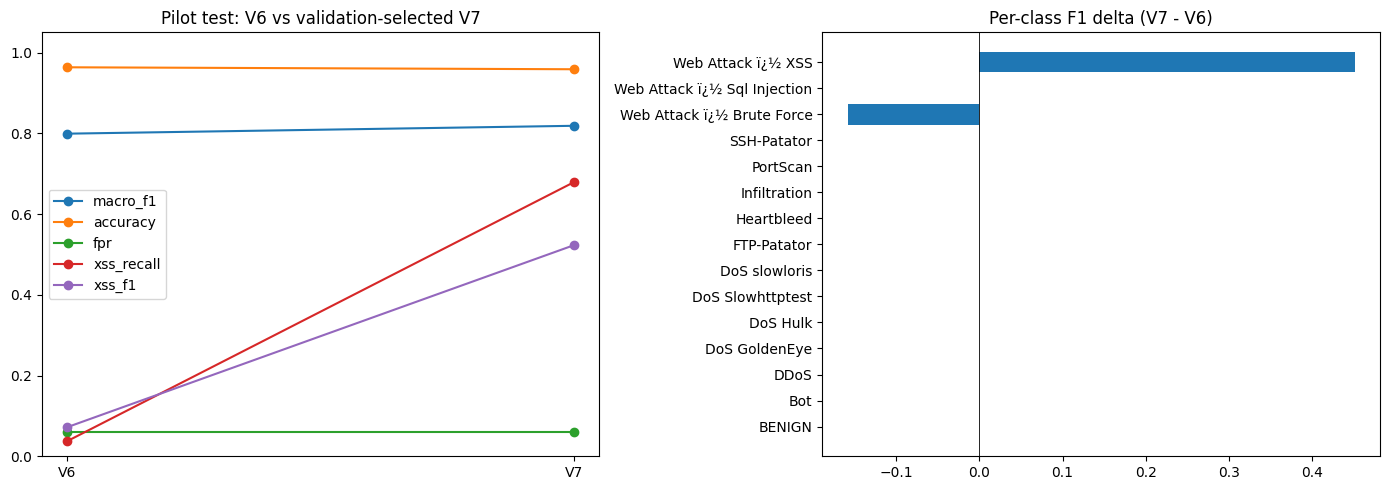

Saved to /kaggle/working/nids_outputs/05_V7_Web_Attack_Specialist files: 22
RESULT: specialist accepted


In [16]:
fig,axs=plt.subplots(1,2,figsize=(14,5))
for key in ['macro_f1','accuracy','fpr','xss_recall','xss_f1']:
    axs[0].plot(['V6','V7'],[base_test_metrics[key],final_test_metrics[key]],marker='o',label=key)
axs[0].set_ylim(0,1.05);axs[0].set_title('Pilot test: V6 vs validation-selected V7');axs[0].legend()
axs[1].barh(class_table['class'],class_table['delta']);axs[1].axvline(0,color='black',lw=.6)
axs[1].set_title('Per-class F1 delta (V7 - V6)');plt.tight_layout()
fig.savefig(OUT/'comparison.png',dpi=150);plt.show()

manifest={'experiment':'05_V7_Web_Attack_Specialist',
 'input_03b':str(p03),'input_v6':str(pv6),'split_sha256':split_sha,
 'feature_variant':variant,'n_features':len(features),'classes':classes,
 'v6_checkpoint_config':vcfg,'v6_base_bias':base_bias,
 'trained_specialists':list(fitted),'selected':selection,
 'limitations':['15-class test previously inspected: exploratory only',
 'specialist trained only on true BF/XSS train; routing uses predictions, not true test labels',
 'SQL Injection too rare for reliable specialized training',
 'No temporal attention, no host/session/time-disjoint data']}
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2,default=str),encoding='utf8')
print('Saved to',OUT,'files:',len(list(OUT.iterdir())))
print('RESULT:', 'specialist accepted' if accept else 'specialist rejected on validation; retained V6')